In [1]:
# importing necessary libraries
import os
import subprocess
import shutil
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import axes
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns
import multiprocessing as mp
from functools import partial
import time
from scipy.interpolate import griddata
import matplotlib.patches as patches

In [ ]:
# set the directory of the files
original_dir = os.getcwd()
data_dir =os.path.abspath("../Result_Files/EP50") 
os.chdir(data_dir)
print(f"Current working directory: {os.getcwd()}")
sim_indentifier = "param_sweep_" + os.path.basename(data_dir)
print(f"Simulation identifier: {sim_indentifier}")

# Create a plot directory if it doesn't exist
plot_dir = os.path.join(original_dir, "Plots_Sensitivity", sim_indentifier)
print(f"plot directory: {plot_dir}")
os.makedirs(plot_dir, exist_ok=True) 

Current working directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm-dev/run/Result_Files_Final/EP50
Simulation identifier: param_sweep_EP50
plot directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm-dev/run/notebooks_post_processing/Plots_Sensitivity/param_sweep_EP50


In [ ]:

combined_data_file = os.path.join(data_dir, "combined_nurse_cell_activation.txt")
germ_summary_file = os.path.join(data_dir, "germ_cell_summary.txt")


germ_summary_df = pd.read_csv(germ_summary_file, sep="\t")


# Read only the first line of the file directly
with open(combined_data_file, "r") as f:
  header_columns = f.readline().strip().split("\t")

# Get the first non-TimeStep column name
first_param_col = next(col for col in header_columns if col != "TimeStep")

# Extract shape from the first word before '_'
shape = first_param_col.split('_')[0]

print(f"Shape extracted from the first parameter column: {shape}")

Shape extracted from the first parameter column: sphere


In [4]:
def set_heatmap_ticks(
    ax, heatmap_data, y_step=10, x_step=0.1, fontsize=24
):
  x_values = heatmap_data.columns.to_numpy().astype(float)
  y_values = heatmap_data.index.to_numpy().astype(float)

  # --- X-axis: 
  x_targets = np.arange(
      np.ceil(x_values.min() / x_step) * x_step,
      np.floor(x_values.max() / x_step) * x_step + x_step / 2,
      x_step,
  )
  x_idx = [np.argmin(np.abs(x_values - t)) for t in x_targets]

  # Deduplicate indices while preserving order
  unique_x_idx, unique_x_labels = [], []
  for idx, t in zip(x_idx, x_targets):
    if idx not in unique_x_idx:
      unique_x_idx.append(idx)
      unique_x_labels.append(f"{t:.1f}")

  ax.set_xticks(np.array(unique_x_idx) + 0.5)
  ax.set_xticklabels(unique_x_labels, fontsize=fontsize)

  # --- Y-axis:
  y_targets = np.arange(
      np.ceil(y_values.min() / y_step) * y_step,
      np.floor(y_values.max() / y_step) * y_step + y_step / 2,
      y_step,
  )
  y_idx = [np.argmin(np.abs(y_values - t)) for t in y_targets]

  # Deduplicate indices while preserving order
  unique_y_idx, unique_y_labels = [], []
  for idx, t in zip(y_idx, y_targets):
    if idx not in unique_y_idx:
      unique_y_idx.append(idx)
      unique_y_labels.append(f"{int(round(t))}")

  ax.set_yticks(np.array(unique_y_idx) + 0.5)
  ax.set_yticklabels(unique_y_labels, fontsize=fontsize)

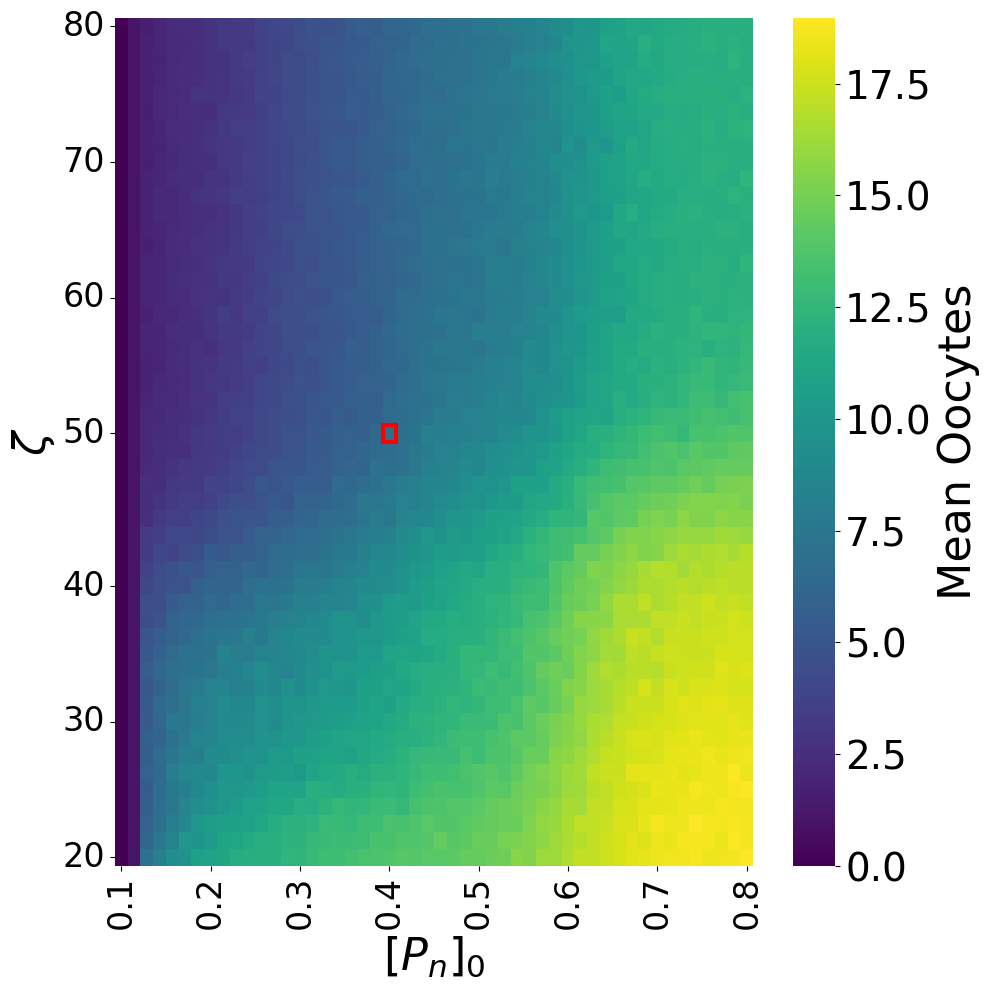

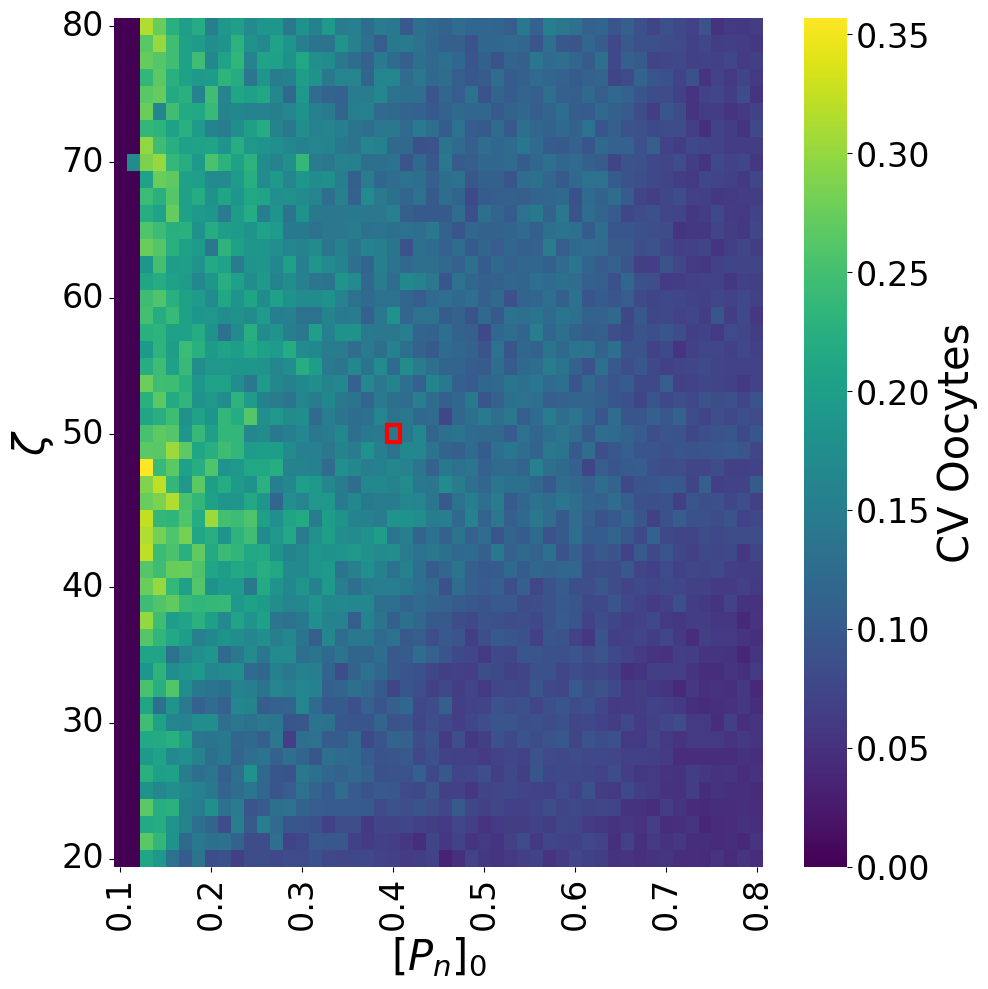

In [ ]:


# Read the germ summary files into DataFrames
germ_summary_df = pd.read_csv(germ_summary_file, sep="\t")
germ_summary_df.columns = germ_summary_df.columns.str.strip()

# Specify exact baseline parameter values
baseline_zeta = 50.0 #  baseline zeta value
baseline_Pn = 0.4 # bqseline P_n0 value

mean_heatmap_data = germ_summary_df.pivot(index="zeta", columns="[P_n]_0", values="Mean_Oocyte") # Panda 2.0 changes
cv_heatmap_data = germ_summary_df.pivot(index="zeta", columns="[P_n]_0", values="CV_Oocyte")

mean_heatmap_data = mean_heatmap_data.iloc[::-1]  # Reverse the order of rows for better visualization
cv_heatmap_data = cv_heatmap_data.iloc[::-1]  # Reverse the order of rows for better visualization

# Locate matrix integer indices for the baseline parameter box
x_pos = np.argmin(np.abs(mean_heatmap_data.columns - baseline_Pn))
y_pos = np.argmin(np.abs(mean_heatmap_data.index - baseline_zeta))

# Create a figure with two subplots for side-by-side heatmaps
fig, ax1 = plt.subplots(1, 1, figsize=(10, 10))

sns.heatmap(mean_heatmap_data, fmt=".2f", cmap="viridis", 
            cbar_kws={'label': 'Mean Activation'}, ax=ax1)

ax1.add_patch(patches.Rectangle((x_pos, y_pos), 1, 1, fill=False, edgecolor='red', lw=3))  # Highlight the baseline point

# Access the colorbar and set font sizes
cbar = ax1.collections[0].colorbar
cbar.ax.tick_params(labelsize=28)         # Set colorbar tick label size
cbar.set_label('Mean Oocytes', size=32)  # Set colorbar label font size
# ax1.set_title("Mean Total Pro-Oocytes", fontsize=34)
ax1.set_xlabel(r"$[P_n]_0$", fontsize=32)
ax1.set_ylabel(r"$\zeta$", fontsize=32)
ax1.tick_params(axis='both', which='major', labelsize=24)  # Larger tick labels

set_heatmap_ticks(ax1, mean_heatmap_data)


plt.tight_layout()
filename = "param_sensitivity_E_P_mean.png"
plt.savefig(os.path.join(plot_dir, filename), dpi=300)
plt.show()

fig, ax2 = plt.subplots(1, 1, figsize=(10, 10))

sns.heatmap(cv_heatmap_data, fmt=".2f", cmap="viridis", 
            cbar_kws={'label': 'CV Activation'}, ax=ax2)

ax2.add_patch(patches.Rectangle((x_pos, y_pos), 1, 1, fill=False, edgecolor='red', lw=3))  # Highlight the baseline point

# Access the colorbar and set font sizes
cbar = ax2.collections[0].colorbar
cbar.ax.tick_params(labelsize=24)         # Set colorbar tick label size
cbar.set_label('CV Oocytes', size=30)  # Set colorbar label font size
# ax2.set_title("CV of Total Pro-Oocytes", fontsize=32)
ax2.set_xlabel(r"$[P_n]_0$", fontsize=30)
ax2.set_ylabel(r"$\zeta$", fontsize=30)
# ax2.tick_params(axis='both', which='major', labelsize=24)  # Larger tick labels


set_heatmap_ticks(ax2, cv_heatmap_data)


plt.tight_layout()
filename = "param_sensitivity_E_P_cv.png"
plt.savefig(os.path.join(plot_dir, filename), dpi=300)
plt.show()



In [ ]:
os.chdir(original_dir) 